1.Haidy Emad Mahmoud Hassan
2.sun-wed 8pm:11pm


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sns.set_style("whitegrid")


In [5]:
df=pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [6]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [7]:
df.sample(7)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2142,29014,Female,23.0,0,0,Yes,Private,Rural,77.73,19.2,never smoked,0
3765,2327,Female,25.0,0,0,No,Private,Rural,76.72,21.5,Unknown,0
38,47306,Male,58.0,0,0,No,Private,Rural,92.62,32.0,Unknown,1
2839,26480,Male,20.0,0,0,No,Private,Rural,100.80,45.9,never smoked,0
5055,11630,Female,25.0,0,0,No,Private,Urban,92.06,25.3,smokes,0
2837,9730,Male,27.0,0,0,Yes,Private,Urban,76.19,22.0,never smoked,0
1979,29863,Male,44.0,0,0,No,Private,Urban,103.44,28.0,never smoked,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [9]:
df.describe().round(2)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


In [10]:
df.shape

(5110, 12)

In [11]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

In [12]:
df.index

RangeIndex(start=0, stop=5110, step=1)

In [13]:
df.dtypes

id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

In [14]:
df['Residence_type'].value_counts()

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

In [15]:
df['ever_married'].value_counts()

ever_married
Yes    3353
No     1757
Name: count, dtype: int64

In [16]:
df['bmi'].value_counts()

bmi
28.7    41
28.4    38
27.7    37
26.7    37
26.1    37
        ..
48.1     1
51.7     1
46.3     1
54.1     1
14.9     1
Name: count, Length: 418, dtype: int64

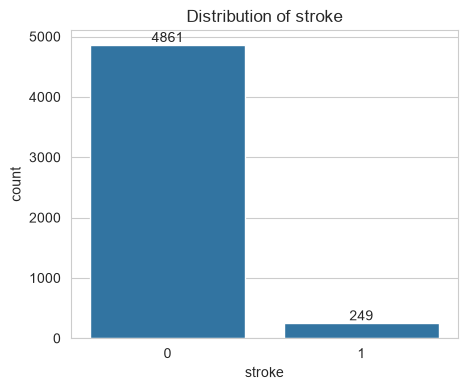

In [17]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="stroke")
ax.bar_label(ax.containers[0])
plt.title("Distribution of stroke")
plt.show()

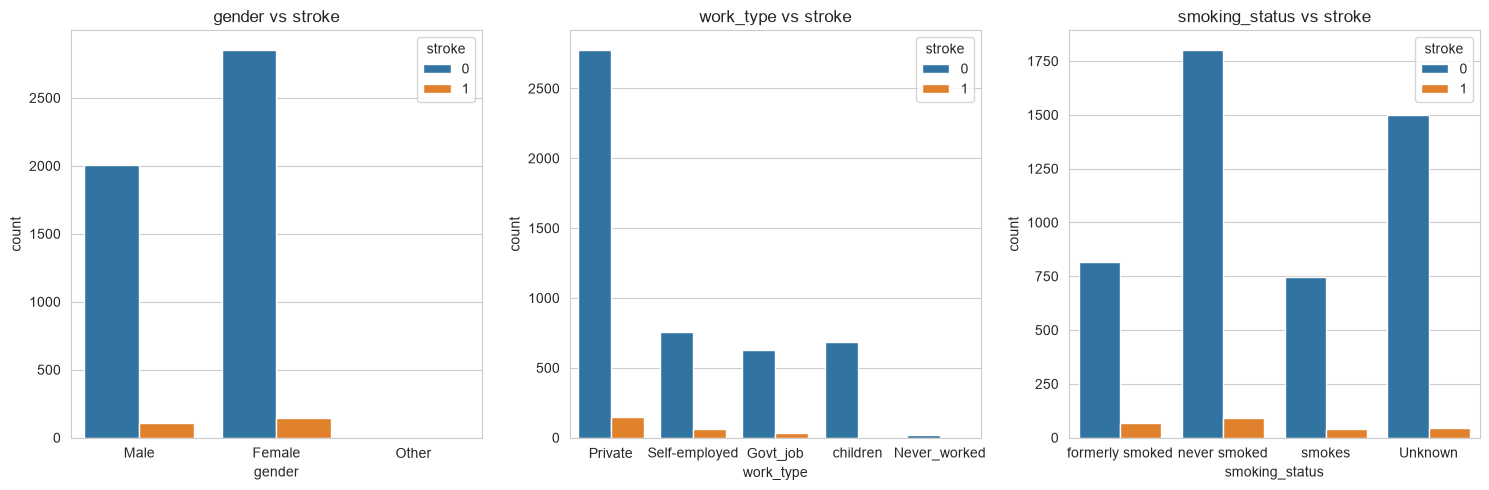

In [19]:
cols = ["gender", "work_type", "smoking_status"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, cols):
    sns.countplot(data=df, x=col, hue="stroke", ax=ax)
    ax.set_title(f"{col} vs stroke")    
plt.tight_layout()
plt.show()

In [20]:
print('value_count before drop:',df["gender"].value_counts())
df = df[df["gender"] != "Other"].reset_index(drop=True)
print('value_count after drop:',df["gender"].value_counts())

value_count before drop: gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
value_count after drop: gender
Female    2994
Male      2115
Name: count, dtype: int64


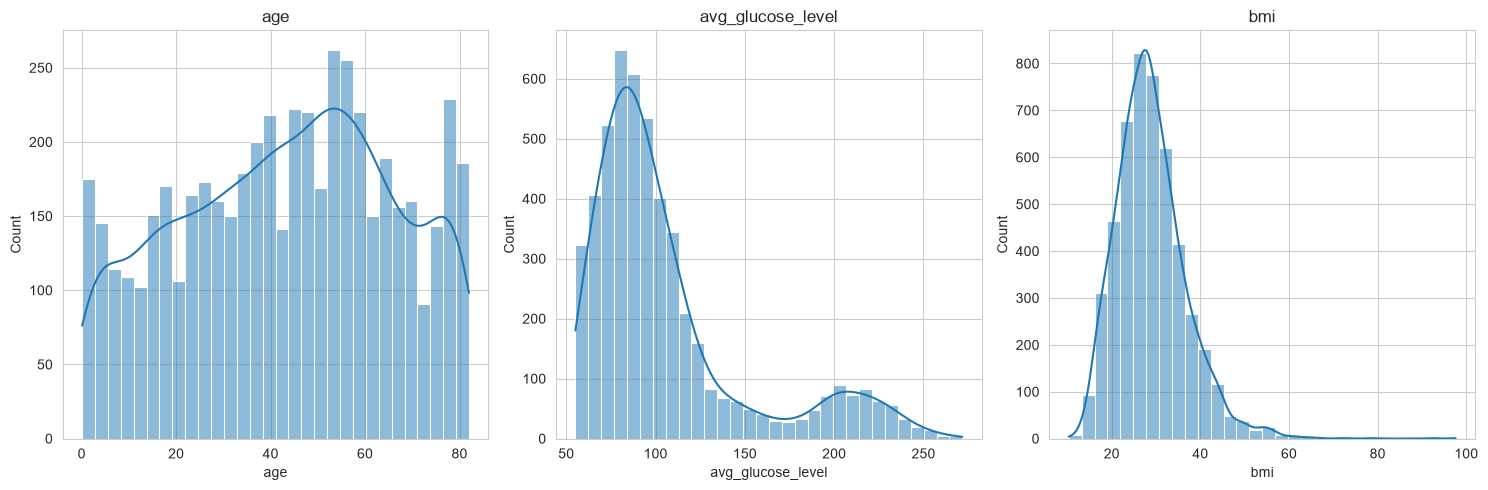

In [21]:
num_cols = ["age", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=ax)
    ax.set_title(f"{col}")
plt.tight_layout()
plt.show()

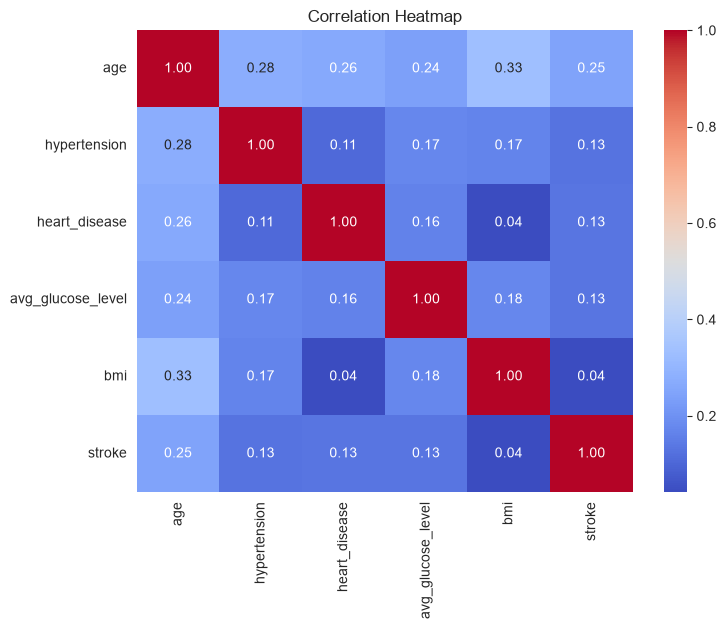

In [22]:
features = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [23]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [24]:
#df['bmi']=df['bmi'].fillna(df['bmi'].median())           # طريقه اخري 
df.fillna({'bmi':df['bmi'].median(),},inplace=True)
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [25]:
df.isnull().sum().sum()

np.int64(0)

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df.drop(columns=['id'],inplace=True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


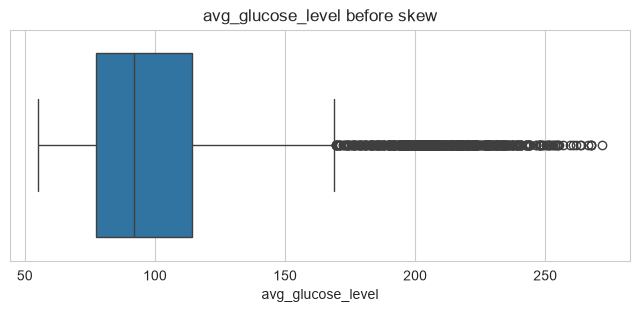

In [28]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df,x="avg_glucose_level")
plt.title("avg_glucose_level before skew")
plt.show()


In [29]:
Q1 = df['avg_glucose_level'].quantile(0.25)
Q3 = df['avg_glucose_level'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR 
upper = Q3 + 1.5 * IQR 
outliers = df[(df['avg_glucose_level'] < lower) |(df['avg_glucose_level'] > upper)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR.round(2))
print("Lower:", lower.round(2))
print("Upper:", upper.round(2))
print("Outliers:", len(outliers))


Q1: 77.24
Q3: 114.09
IQR: 36.85
Lower: 21.96
Upper: 169.36
Outliers: 627


In [30]:
df['avg_glucose_level']=np.log1p(df['avg_glucose_level'])

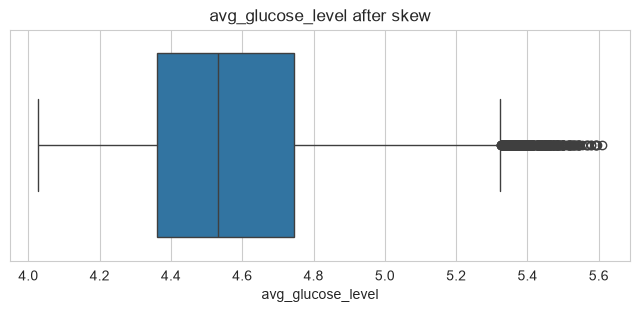

In [31]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df,x="avg_glucose_level")
plt.title("avg_glucose_level after skew")
plt.show()

In [32]:

df["gender"] = df["gender"].map({"Male": 0, "Female": 1})
df["ever_married"] = df["ever_married"].map({"Yes": 1, "No": 0})
df["Residence_type"] = df["Residence_type"].map({"Rural": 0, "Urban": 1})

In [33]:
df = df.reset_index(drop=True)
df = pd.get_dummies(df, columns=["work_type", "smoking_status","gender","ever_married","Residence_type"], drop_first=True, dtype=int)
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,gender_1,ever_married_1,Residence_type_1
0,67.0,0,1,5.436731,36.6,1,0,1,0,0,1,0,0,0,1,1
1,61.0,0,0,5.314240,28.1,1,0,0,1,0,0,1,0,1,1,0
2,80.0,0,1,4.672081,32.5,1,0,1,0,0,0,1,0,0,1,0
3,49.0,0,0,5.148831,34.4,1,0,1,0,0,0,0,1,1,1,1
4,79.0,1,0,5.165471,24.0,1,0,0,1,0,0,1,0,1,1,0


In [34]:
df.shape

(5109, 16)

In [35]:
X = df.drop(columns=["stroke"])
y = df["stroke"]
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)
print('x_train:',X_train.shape)
print('y_train:',y_train.shape)
print('x_test:',X_test.shape)
print('y_test:',y_test.shape)

x_train: (4087, 15)
y_train: (4087,)
x_test: (1022, 15)
y_test: (1022,)


In [36]:
colus=[ 'age', 'avg_glucose_level', 'bmi']
scaler= StandardScaler()
X_train_scale=X_train.copy()
X_test_scale=X_test.copy()
X_train_scale[colus]=scaler.fit_transform(X_train[colus])
X_test_scale[colus]=scaler.transform(X_test[colus])


In [37]:
X_train_scale[colus].describe().loc[["mean", "std","max","min"]].round(2)

,age,avg_glucose_level,bmi
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
max,1.71,2.84,8.89
min,-1.91,-1.61,-2.40


In [38]:
rse = RandomOverSampler(random_state=42)
X_rse, y_rse = rse.fit_resample(X_train_scale, y_train)
print(y_rse.value_counts())

stroke
0    3888
1    3888
Name: count, dtype: int64


In [39]:
rsu = RandomUnderSampler(random_state=42)
X_rsu, y_rsu = rsu.fit_resample(X_train_scale, y_train)
print(y_rsu.value_counts())

stroke
0    199
1    199
Name: count, dtype: int64


In [42]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scale, y_train)
print(X_train_balanced.shape , y_train_balanced.shape)

(7776, 15) (7776,)


        before  RandomOverSampler  RandomUnderSampler  SMOTE
stroke                                                      
0         3888               3888                 199   3888
1          199               3888                 199   3888


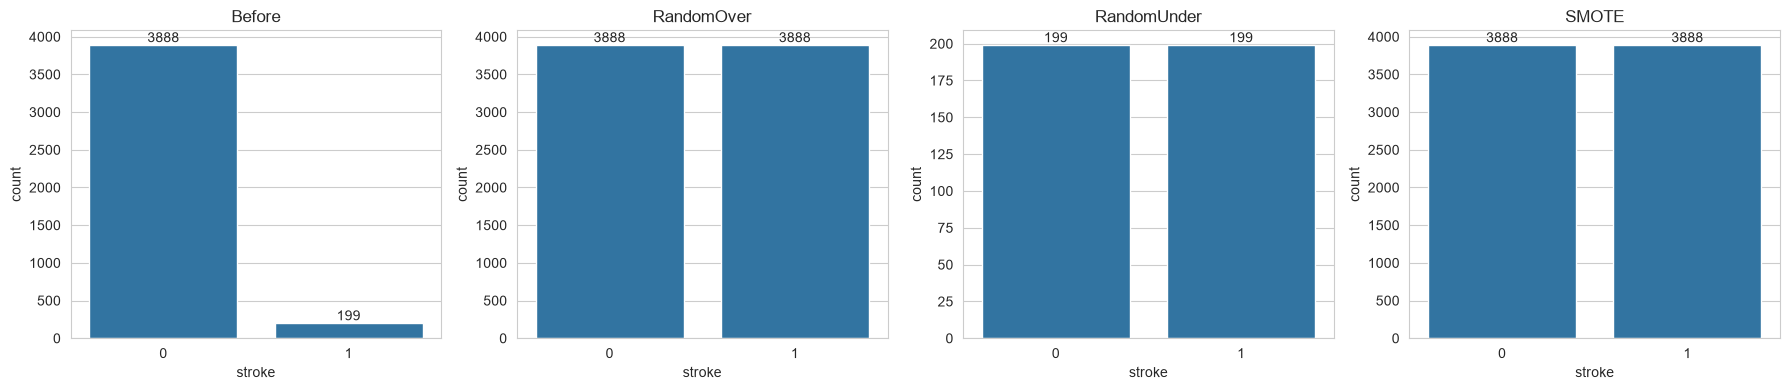

In [49]:
sizes = pd.DataFrame({
    'before': y_train.value_counts(),
    'RandomOverSampler': y_rse.value_counts(),
    'RandomUnderSampler': y_rsu.value_counts(),
    'SMOTE': y_train_balanced.value_counts(),
})
print(sizes)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, y) in zip(axes, [('Before', y_train), ('RandomOver', y_rse), ('RandomUnder', y_rsu), ('SMOTE', y_train_balanced)]):
    sns.countplot(x=y, ax=ax) 
    ax.set_title(name)
    ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

In [43]:
print(y_train.value_counts())

stroke
0    3888
1     199
Name: count, dtype: int64


 high-risk stroke: كبار السن وخاصه الرجال اللي فوق 60 عندهم مشكله في ارتفاع ضغط الدم و عندهم مشكله في القلب ولو كان بيدخن  او بيدخن ده بيخلي انه احتمال كبير انه يحصله جلطه دماغيه 



عوامل الخطر: العمر هو العامل الأكثر تأثيراً، تليه الأمراض المزمنة (كالضغط والقلب)، ثم ارتفاع السكر والتدخين
عدم توازن الفئات كانت البيانات غير متوازنة بشكل كبير، حيث فاق عدد غير المصابين عدد المصابين بكثير
تأثير المعالجة: تم تطبيق تقنية SMOTE على بيانات التدريب فقط لموازنة الفئات ومنع الموديل من التحيز، مما حسّن دقته